In [1]:
!pip install -q kagglehub
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import kagglehub
path = kagglehub.dataset_download(
    "kazanova/sentiment140"
)
print("Dataset path:")
print(path)

Using Colab cache for faster access to the 'sentiment140' dataset.
Dataset path:
/kaggle/input/sentiment140


In [2]:
import os
print(os.listdir(path))

['training.1600000.processed.noemoticon.csv']


In [3]:
file_path = os.path.join(
    path,
    "training.1600000.processed.noemoticon.csv"
)

In [4]:
df = pd.read_csv(
    file_path,
    encoding="latin-1",
    header=None
)
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1600000, 6)


,0,1,2,3,4,5
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."


In [5]:
df.columns = [
    "sentiment",
    "id",
    "date",
    "query",
    "username",
    "tweet"
]
display(df.head())

,sentiment,id,date,query,username,tweet
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all...."


In [7]:
df["sentiment"] = df["sentiment"].replace({
    0: 0,
    4: 1
})
print(df["sentiment"].value_counts())

sentiment
0    800000
1    800000
Name: count, dtype: int64


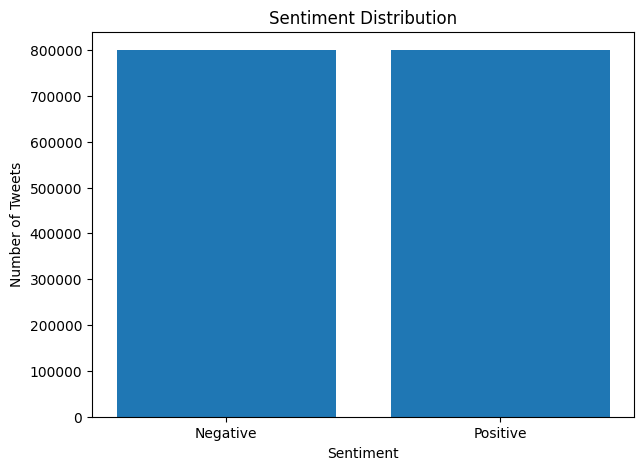

In [8]:
sentiment_counts = df["sentiment"].value_counts()
plt.figure(figsize=(7, 5))
plt.bar(
    ["Negative", "Positive"],
    [
        sentiment_counts.get(0, 0),
        sentiment_counts.get(1, 0)
    ]
)

plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.title("Sentiment Distribution")

plt.show()

In [9]:
def clean_tweet(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove hashtag symbol but keep the word
    text = re.sub(r"#", "", text)

    # Remove RT
    text = re.sub(r"\brt\b", "", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [10]:
df["clean_tweet"] = df["tweet"].apply(clean_tweet)
display(
    df[["tweet", "clean_tweet"]].head(10)
)

,tweet,clean_tweet
0,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",a thats a bummer you shoulda got david carr of...
1,is upset that he can't update his Facebook by ...,is upset that he cant update his facebook by t...
2,@Kenichan I dived many times for the ball. Man...,i dived many times for the ball managed to sav...
3,my whole body feels itchy and like its on fire,my whole body feels itchy and like its on fire
4,"@nationwideclass no, it's not behaving at all....",no its not behaving at all im mad why am i her...
5,@Kwesidei not the whole crew,not the whole crew
6,Need a hug,need a hug
7,@LOLTrish hey long time no see! Yes.. Rains a...,hey long time no see yes rains a bit only a bi...
8,@Tatiana_K nope they didn't have it,nope they didnt have it
9,@twittera que me muera ?,que me muera


In [11]:
df = df[df["clean_tweet"].str.len() > 0]
print("Dataset after cleaning:", df.shape)

Dataset after cleaning: (1596302, 7)


In [12]:
X = df["clean_tweet"]
y = df["sentiment"]
print("Features:")
print(X.head())
print("\nLabels:")
print(y.head())

Features:
0    a thats a bummer you shoulda got david carr of...
1    is upset that he cant update his facebook by t...
2    i dived many times for the ball managed to sav...
3       my whole body feels itchy and like its on fire
4    no its not behaving at all im mad why am i her...
Name: clean_tweet, dtype: object

Labels:
0    0
1    0
2    0
3    0
4    0
Name: sentiment, dtype: int64


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1277041
Testing samples: 319261


In [14]:
tfidf = TfidfVectorizer(
    max_features=50000,
    stop_words="english",
    ngram_range=(1, 2)
)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1277041, 50000)
Testing TF-IDF shape: (319261, 50000)


In [15]:
feature_names = tfidf.get_feature_names_out()
print("Number of TF-IDF features:")
print(len(feature_names))
print("\nFirst 50 features:")
print(feature_names[:50])

Number of TF-IDF features:
50000

First 50 features:
['aa' 'aaa' 'aaaa' 'aaaaa' 'aaaaaa' 'aaaaaah' 'aaaaah' 'aaaaand' 'aaaah'
 'aaaahhh' 'aaaand' 'aaaargh' 'aaaaw' 'aaah' 'aaahh' 'aaahhh' 'aaahhhh'
 'aaand' 'aaargh' 'aaaw' 'aaaww' 'aah' 'aahh' 'aahhh' 'aaliyah' 'aampe'
 'aand' 'aar' 'aargh' 'aaron' 'aarons' 'aaw' 'aaww' 'aawww' 'ab' 'abandon'
 'abandoned' 'abandoning' 'abba' 'abbey' 'abbie' 'abby' 'abc' 'abc family'
 'abd' 'aber' 'abercrombie' 'aberdeen' 'abi' 'abilities']


In [16]:
model = LogisticRegression(
    max_iter=1000
)
model.fit(
    X_train_tfidf,
    y_train
)
print("Model training completed.")

Model training completed.


In [17]:
y_pred = model.predict(X_test_tfidf)
print("Predictions generated.")
print("\nFirst 20 predictions:")
print(y_pred[:20])
print("\nActual labels:")
print(y_test.iloc[:20].values)

Predictions generated.

First 20 predictions:
[1 0 0 1 1 1 0 1 0 1 0 0 1 0 1 1 1 0 0 1]

Actual labels:
[0 0 0 1 0 0 1 0 1 1 0 0 1 0 1 0 1 1 0 0]


In [18]:
accuracy = accuracy_score(
    y_test,
    y_pred
)
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 0.7838
Accuracy: 78.38%


In [19]:
precision = precision_score(
    y_test,
    y_pred
)
print(f"Precision: {precision:.4f}")

Precision: 0.7715


In [20]:
recall = recall_score(
    y_test,
    y_pred
)
print(f"Recall: {recall:.4f}")

Recall: 0.8063


In [21]:
f1 = f1_score(
    y_test,
    y_pred
)
print(f"F1-score: {f1:.4f}")

F1-score: 0.7885


In [22]:
print("========== MODEL PERFORMANCE ==========")
print(f"Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision : {precision * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-score  : {f1 * 100:.2f}%")

========== MODEL PERFORMANCE ==========
Accuracy  : 78.38%
Precision : 77.15%
Recall    : 80.63%
F1-score  : 78.85%


In [23]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Negative",
            "Positive"
        ]
    )
)

              precision    recall  f1-score   support

    Negative       0.80      0.76      0.78    159664
    Positive       0.77      0.81      0.79    159597

    accuracy                           0.78    319261
   macro avg       0.78      0.78      0.78    319261
weighted avg       0.78      0.78      0.78    319261



In [24]:
cm = confusion_matrix(
    y_test,
    y_pred
)
print(cm)

[[121555  38109]
 [ 30913 128684]]


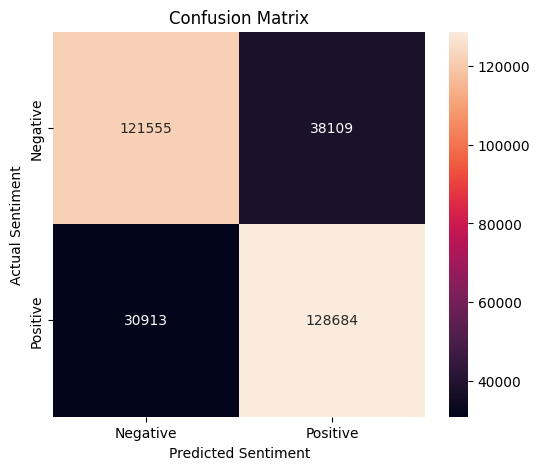

In [25]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Confusion Matrix")
plt.show()

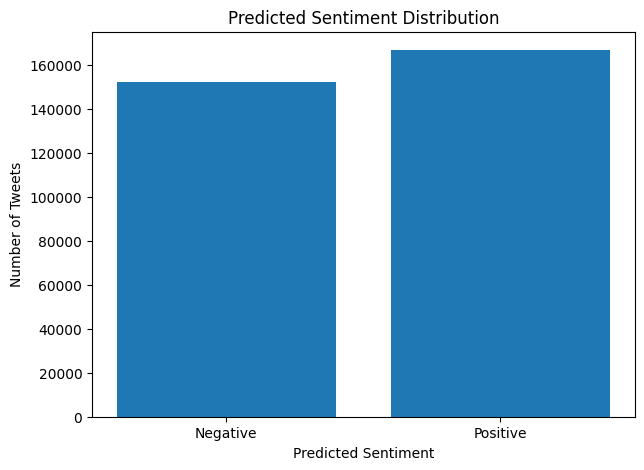

In [26]:
predicted_counts = pd.Series(y_pred).value_counts()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Negative", "Positive"],
    [
        predicted_counts.get(0, 0),
        predicted_counts.get(1, 0)
    ]
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Number of Tweets")
plt.title("Predicted Sentiment Distribution")

plt.show()

In [27]:
new_tweets = [
    "I absolutely love this product, it is amazing!",
    "This is the worst experience I have ever had.",
    "The product is excellent and works perfectly.",
    "I am very disappointed and unhappy with this."
]

# Clean tweets
clean_new_tweets = [
    clean_tweet(tweet)
    for tweet in new_tweets
]

# Convert to TF-IDF
new_tweets_tfidf = tfidf.transform(
    clean_new_tweets
)

# Predict
predictions = model.predict(
    new_tweets_tfidf
)

print("========== SENTIMENT PREDICTIONS ==========\n")

for tweet, prediction in zip(
    new_tweets,
    predictions
):

    sentiment = (
        "Positive"
        if prediction == 1
        else "Negative"
    )

    print("Tweet:", tweet)
    print("Sentiment:", sentiment)
    print()

========== SENTIMENT PREDICTIONS ==========

Tweet: I absolutely love this product, it is amazing!
Sentiment: Positive

Tweet: This is the worst experience I have ever had.
Sentiment: Negative

Tweet: The product is excellent and works perfectly.
Sentiment: Positive

Tweet: I am very disappointed and unhappy with this.
Sentiment: Negative



In [28]:
probabilities = model.predict_proba(
    new_tweets_tfidf
)

for tweet, prediction, probability in zip(
    new_tweets,
    predictions,
    probabilities
):

    sentiment = (
        "Positive"
        if prediction == 1
        else "Negative"
    )

    confidence = max(probability) * 100

    print("Tweet:", tweet)
    print("Sentiment:", sentiment)
    print(f"Confidence: {confidence:.2f}%")
    print()

Tweet: I absolutely love this product, it is amazing!
Sentiment: Positive
Confidence: 97.92%

Tweet: This is the worst experience I have ever had.
Sentiment: Negative
Confidence: 91.42%

Tweet: The product is excellent and works perfectly.
Sentiment: Positive
Confidence: 98.49%

Tweet: I am very disappointed and unhappy with this.
Sentiment: Negative
Confidence: 99.91%

